In [1]:

import pandas as pd
import numpy as np
from susceptibility_metrics import *

user_profile_path = '../data/results/mal/user_profiles.tsv'

recommender_profiles_path = '../data/results/mal/recommender_profiles_10.tsv'

user_profiles = pd.read_csv(user_profile_path, delimiter='\t')

recommender_profiles = pd.read_csv(recommender_profiles_path, delimiter='\t')

user_profiles['age'] = user_profiles['age'].astype(int)

algorithm = 'RP3beta'

In [2]:
child_user_ids = user_profiles[user_profiles['age'] < 18]['user_id'].to_list()

user_profiles = user_profiles[user_profiles['user_id'].isin(child_user_ids)]

recommender_profiles = recommender_profiles[recommender_profiles['user_id'].isin(child_user_ids)]

recommender_profiles = recommender_profiles.drop(columns=[col for col in recommender_profiles.columns if ((algorithm not in col) and (col != 'user_id'))])

recommender_profiles.columns = [col if col == 'user_id' else col.split(f'{algorithm}_')[-1] + '_rec' for col in recommender_profiles.columns]

In [3]:
user_ids = set(user_profiles['user_id'].to_list())
rec_user_ids = set(recommender_profiles['user_id'].to_list())
uncommon_user_ids = user_ids - rec_user_ids
print(len(uncommon_user_ids))
# should be 0, meaning all child users have a recommender profile

df = pd.merge(user_profiles, recommender_profiles, on='user_id', how='inner')

0


In [4]:
df.columns

Index(['user_id', 'gender', 'location', 'birth_date', 'age', 'num_items',
       'perc_comedy', 'perc_action', 'perc_drama', 'perc_romance', 'perc_kids',
       'perc_fantasy', 'perc_horror', 'perc_hentai', 'perc_R', 'perc_Rplus',
       'perc_Rx', 'perc_R_Rplus_Rx', 'syn_sexual_rec', 'syn_violence_rec',
       'image_nsfw_rec', 'perc_R_rec', 'perc_Rplus_rec', 'perc_Rx_rec',
       'perc_R_Rplus_Rx_rec'],
      dtype='str')

In [5]:
susceptibility_estimation(
    df=df,
    characteristic_col = 'age',
    output_col = 'syn_sexual_rec',
trait_type = 'continuous',
)

(    trait_value     n  susceptibility  ci_lower  ci_upper
 0     13.000000  6503        0.015547  0.008900  0.027021
 1     13.040404  6503        0.015606  0.008993  0.026950
 2     13.080808  6503        0.015665  0.009086  0.026879
 3     13.121212  6503        0.015725  0.009180  0.026808
 4     13.161616  6503        0.015785  0.009276  0.026738
 ..          ...   ...             ...       ...       ...
 95    16.838384  6503        0.022278  0.018192  0.027258
 96    16.878788  6503        0.022363  0.018189  0.027466
 97    16.919192  6503        0.022447  0.018184  0.027681
 98    16.959596  6503        0.022532  0.018177  0.027901
 99    17.000000  6503        0.022617  0.018167  0.028126
 
 [100 rows x 5 columns],
 <statsmodels.genmod.generalized_linear_model.GLMResultsWrapper at 0x24d6b44eba0>)

In [6]:
#for char_col in ['age', 'num_items', 'perc_R_Rplus_Rx', 'perc_comedy', 'perc_action', 'perc_hentai', 'perc_kids']:
char_col = 'gender'
out_col = 'image_nsfw_rec'
tt = 'categorical'

pred, summary, fig = assess_disproportionate_susceptibility(
    df=df,
    characteristic_col = char_col,
    output_col = out_col,
    trait_type=tt,
    continuous_model="spline",
    spline_df=4
    )



# if fig is not None:

#     fig.savefig(f'../results/{out_col}_by_{char_col}.pdf', bbox_inches='tight', pad_inches = 0)
#     fig.savefig(f'../results/{out_col}_by_{char_col}.svg', bbox_inches='tight', pad_inches = 0)


BASELINE SUSCEPTIBILITY
Baseline susceptibility : 0.0068
Standard deviation      : 0.0371
Disproportionality threshold (+1 SD): 0.0439

TRAIT VALUE SUSCEPTIBILITY
trait_value    n  susceptibility  ci_lower  ci_upper  relative_susceptibility criterion
     Female 2119          0.0082    0.0052    0.0131                   0.0014      NONE
       Male 4325          0.0062    0.0042    0.0090                  -0.0007      NONE
 Non-Binary   59          0.0042    0.0001    0.1801                  -0.0027      NONE



BASELINE SUSCEPTIBILITY
Baseline susceptibility : 0.0068
Standard deviation      : 0.0371
Disproportionality threshold (+1 SD): 0.0439


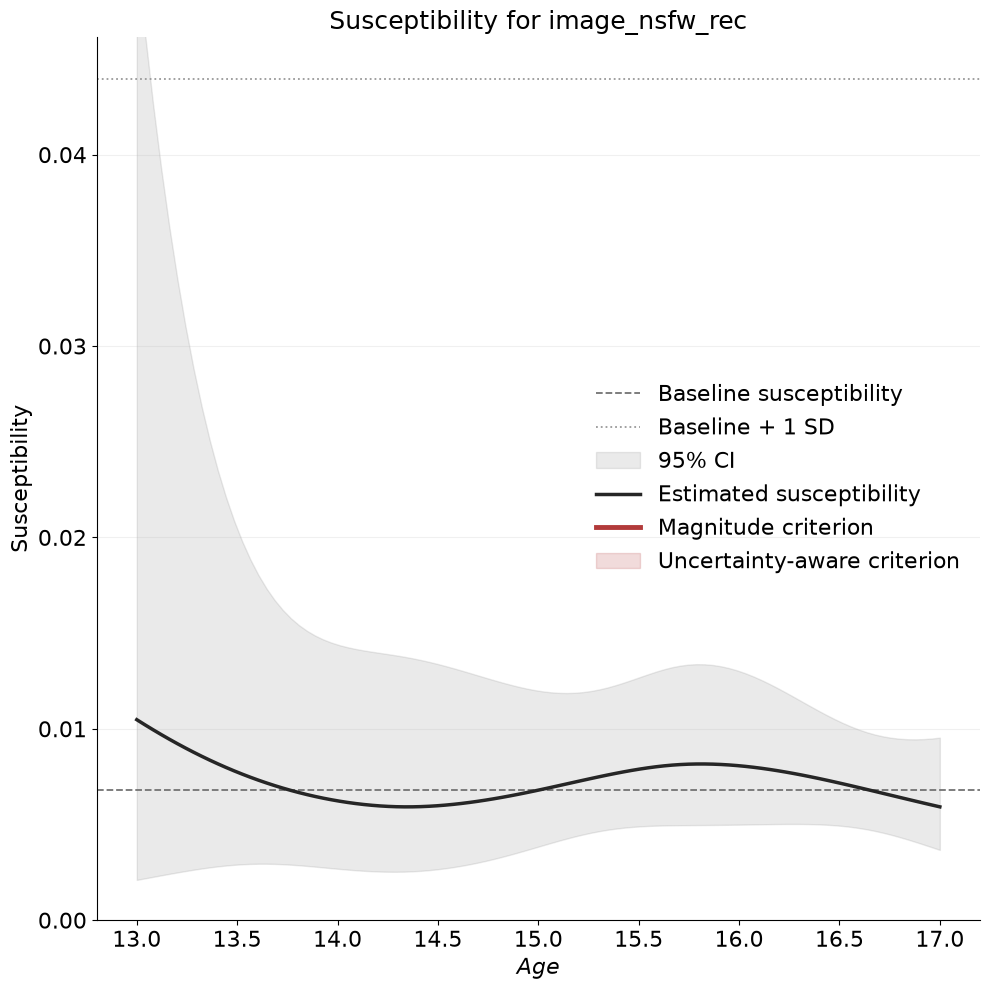

AIC: 468.63

Magnitude criterion intervals:
  None

Uncertainty-aware criterion intervals:
  None

Maximum predicted susceptibility:
    X = 13.0000
    Predicted Y = 0.0105
    Increase= 0.0037; percentage: 53.5639%

BASELINE SUSCEPTIBILITY
Baseline susceptibility : 0.0068
Standard deviation      : 0.0371
Disproportionality threshold (+1 SD): 0.0439


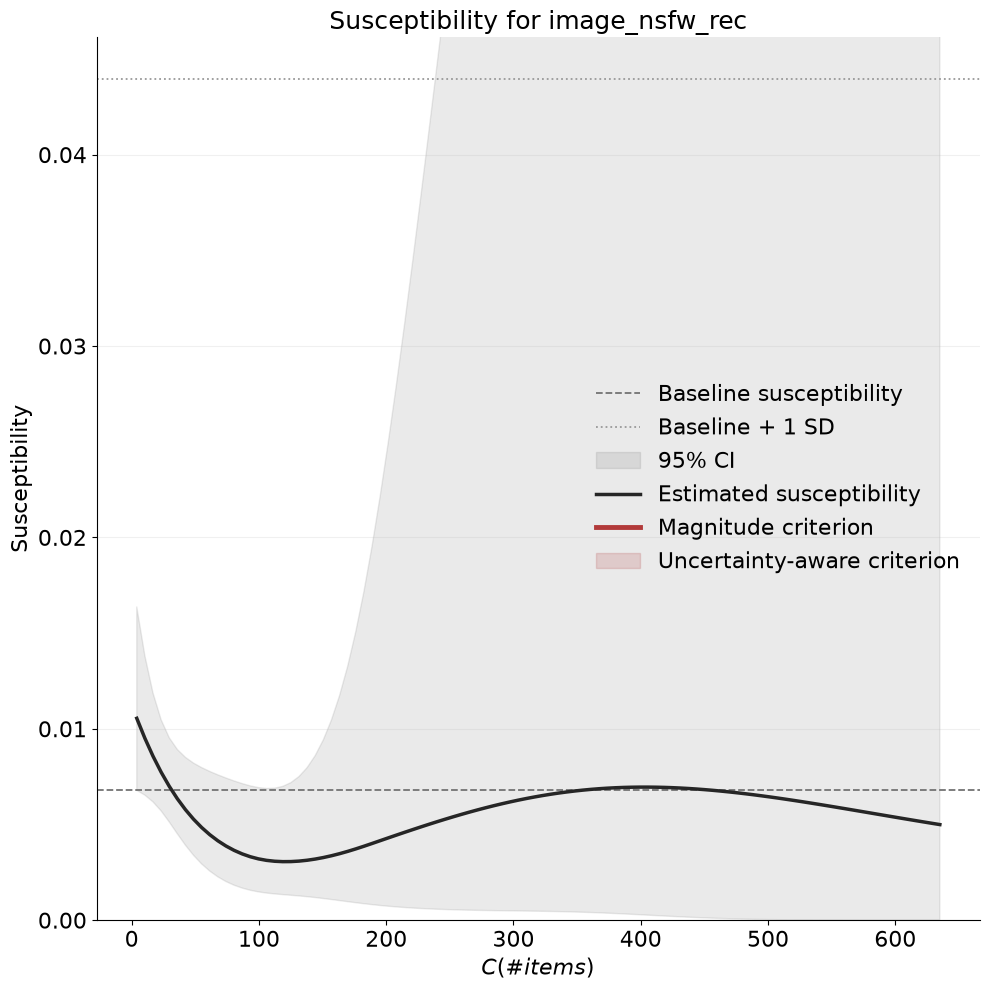

AIC: 463.98

Magnitude criterion intervals:
  None

Uncertainty-aware criterion intervals:
  None

Maximum predicted susceptibility:
    X = 4.0000
    Predicted Y = 0.0105
    Increase= 0.0037; percentage: 54.6291%

BASELINE SUSCEPTIBILITY
Baseline susceptibility : 0.0068
Standard deviation      : 0.0371
Disproportionality threshold (+1 SD): 0.0439


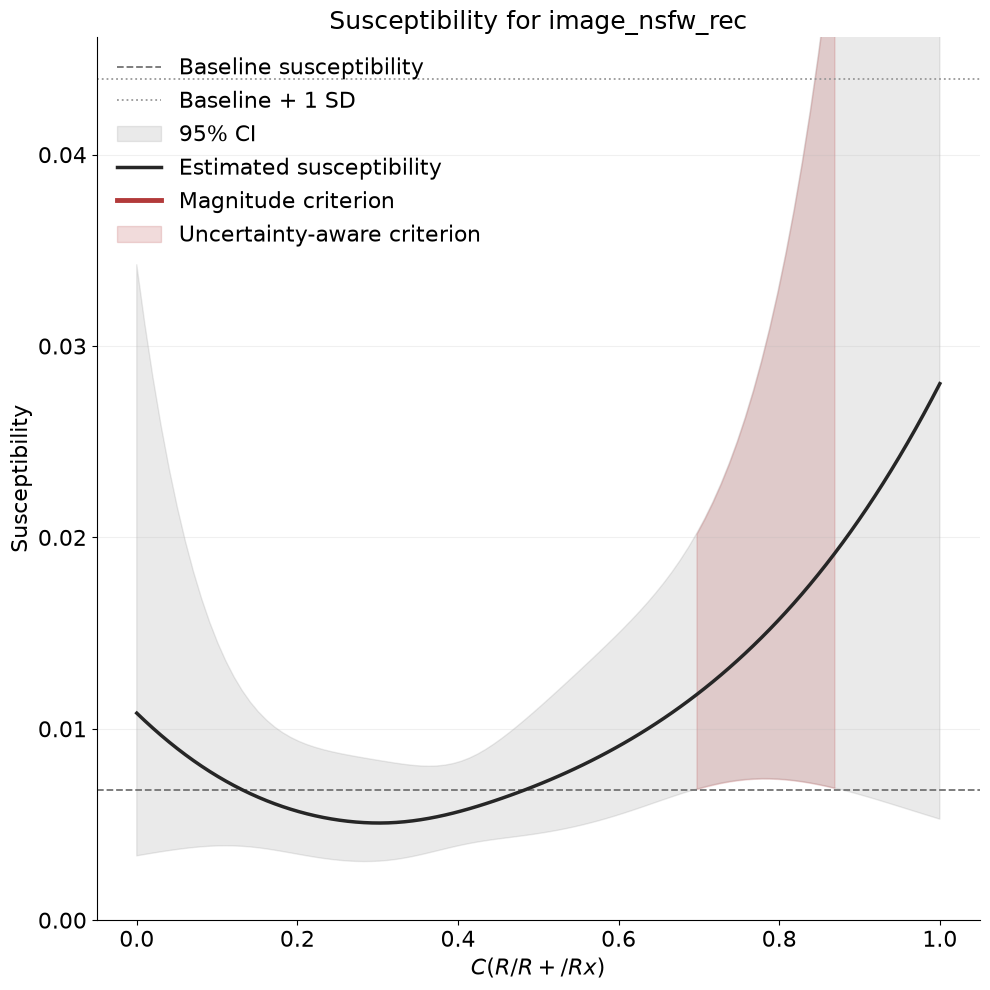

AIC: 464.67

Magnitude criterion intervals:
  None

Uncertainty-aware criterion intervals:
X: 0.6970 – 0.8687
Y: 0.0118 – 0.0191

Maximum predicted susceptibility:
    X = 1.0000
    Predicted Y = 0.0280
    Increase= 0.0212; percentage: 310.9900%

BASELINE SUSCEPTIBILITY
Baseline susceptibility : 0.0068
Standard deviation      : 0.0371
Disproportionality threshold (+1 SD): 0.0439


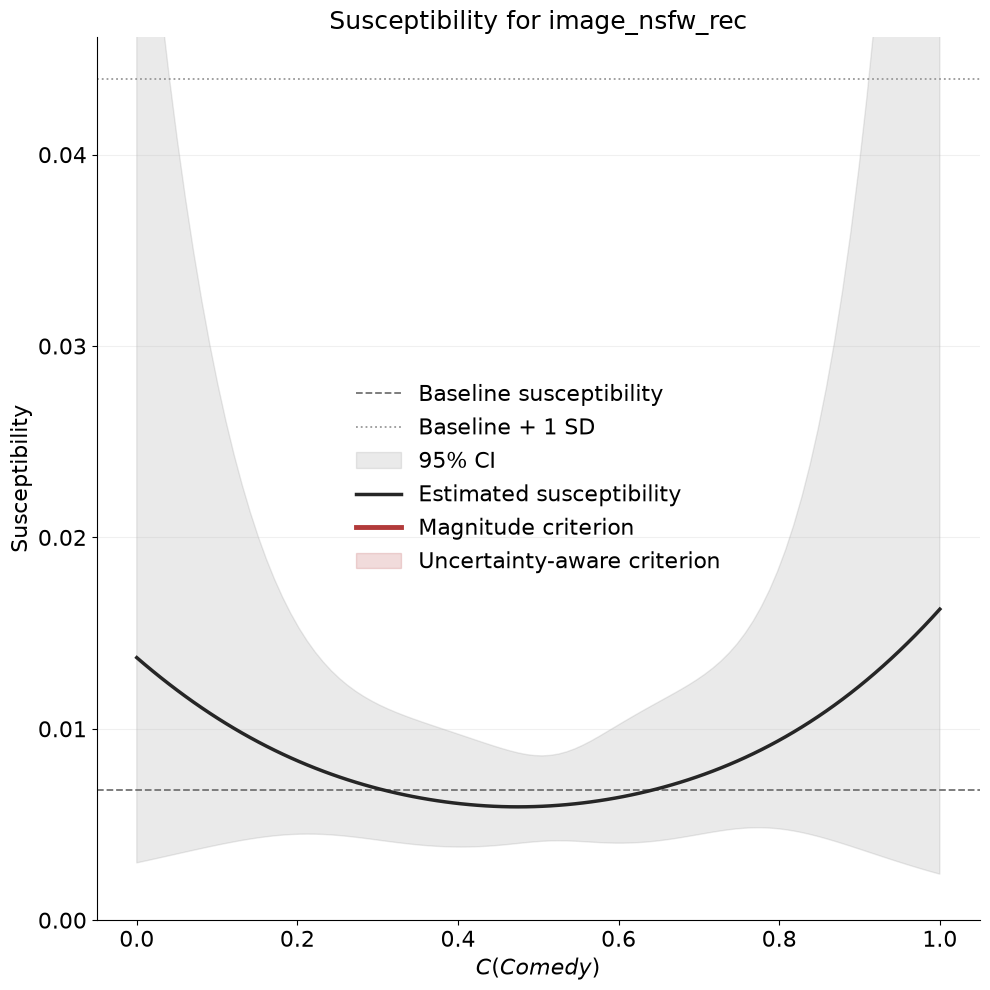

AIC: 467.94

Magnitude criterion intervals:
  None

Uncertainty-aware criterion intervals:
  None

Maximum predicted susceptibility:
    X = 1.0000
    Predicted Y = 0.0163
    Increase= 0.0094; percentage: 138.2416%

BASELINE SUSCEPTIBILITY
Baseline susceptibility : 0.0068
Standard deviation      : 0.0371
Disproportionality threshold (+1 SD): 0.0439


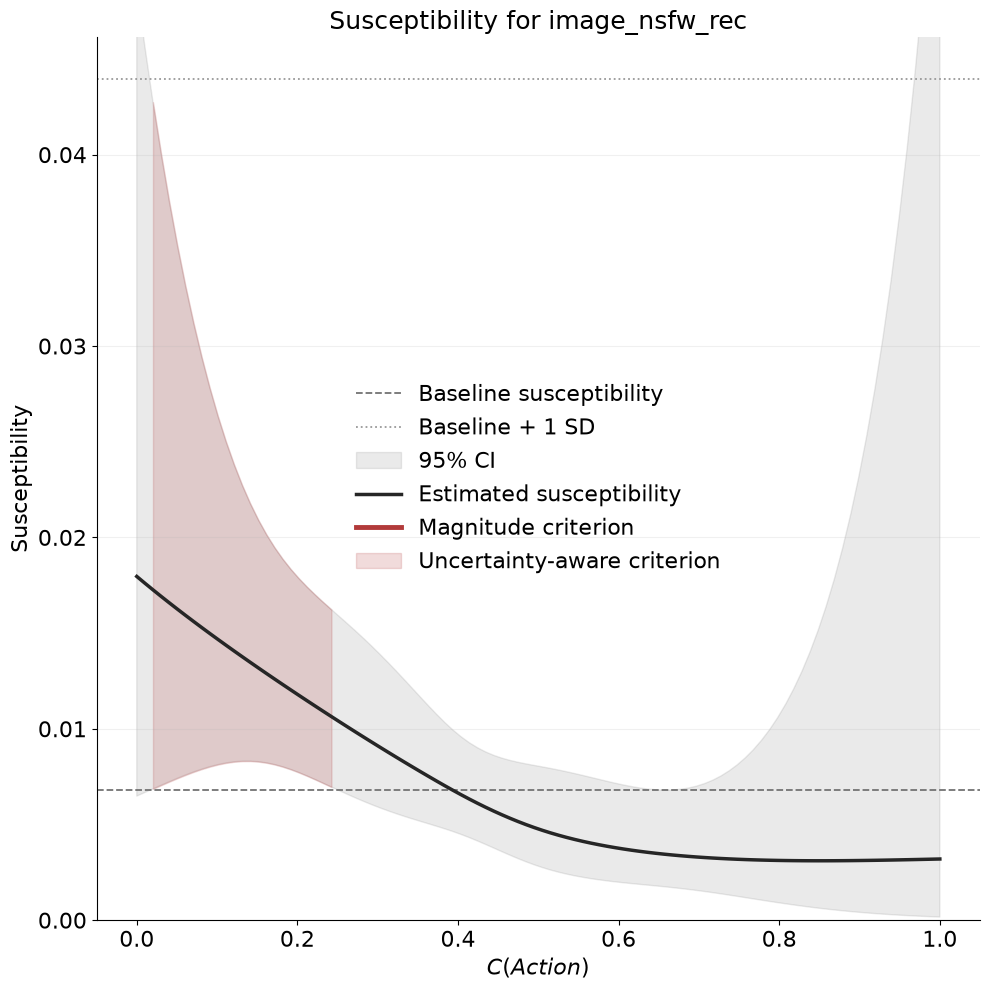

AIC: 459.62

Magnitude criterion intervals:
  None

Uncertainty-aware criterion intervals:
X: 0.0202 – 0.2424
Y: 0.0173 – 0.0106

Maximum predicted susceptibility:
    X = 0.0000
    Predicted Y = 0.0180
    Increase= 0.0111; percentage: 163.2952%

BASELINE SUSCEPTIBILITY
Baseline susceptibility : 0.0068
Standard deviation      : 0.0371
Disproportionality threshold (+1 SD): 0.0439


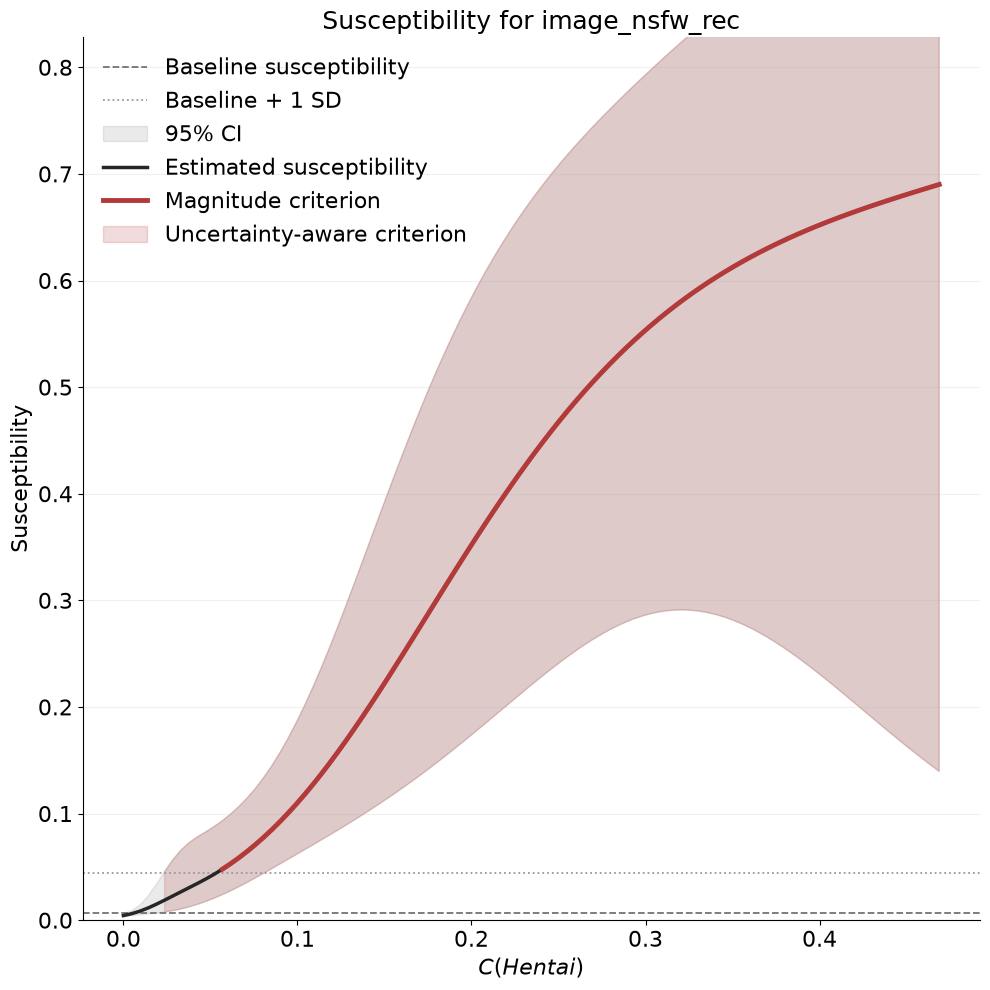

AIC: 387.08

Magnitude criterion intervals:
X: 0.0568 – 0.4688
Y: 0.0478 – 0.6901

Uncertainty-aware criterion intervals:
X: 0.0237 – 0.4688
Y: 0.0188 – 0.6901

Maximum predicted susceptibility:
    X = 0.4688
    Predicted Y = 0.6901
    Increase= 0.6833; percentage: 10016.4871%

BASELINE SUSCEPTIBILITY
Baseline susceptibility : 0.0068
Standard deviation      : 0.0371
Disproportionality threshold (+1 SD): 0.0439


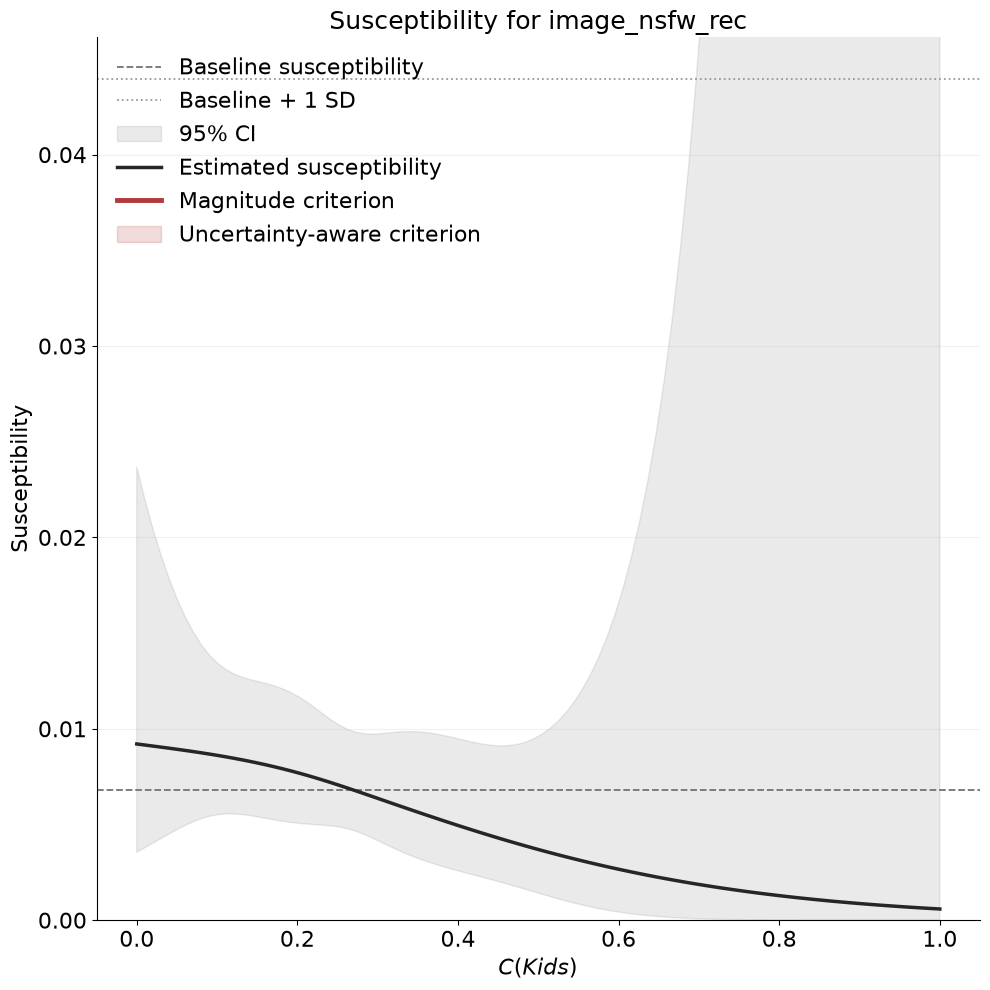

AIC: 466.82

Magnitude criterion intervals:
  None

Uncertainty-aware criterion intervals:
  None

Maximum predicted susceptibility:
    X = 0.0000
    Predicted Y = 0.0092
    Increase= 0.0024; percentage: 34.9695%


In [7]:
for char_col in ['age', 'num_items', 'perc_R_Rplus_Rx', 'perc_comedy', 'perc_action', 'perc_hentai', 'perc_kids']:
    #char_col = 'perc_comedy'
    out_col = 'image_nsfw_rec'
    tt = 'continuous'

    pred, summary, fig = assess_disproportionate_susceptibility(
        df=df,
        characteristic_col = char_col,
        output_col = out_col,
        trait_type=tt,
        continuous_model="spline",
        spline_df=4
        )



    if fig is not None:

        fig.savefig(f'../results/{out_col}_by_{char_col}.pdf', bbox_inches='tight', pad_inches = 0)
        fig.savefig(f'../results/{out_col}_by_{char_col}.svg', bbox_inches='tight', pad_inches = 0)

findfont: Failed to find font weight medium, now using 400.



INTERSECTIONAL SUSCEPTIBILITY
Traits                  : age × gender
Baseline susceptibility : 0.4383
Standard deviation      : 0.2024
+1 SD threshold     : 0.6407

Magnitude criterion satisfied at 1 of 15 prediction points.
Uncertainty-aware criterion satisfied at 2 of 15 prediction points.
AIC                     : 6292.40


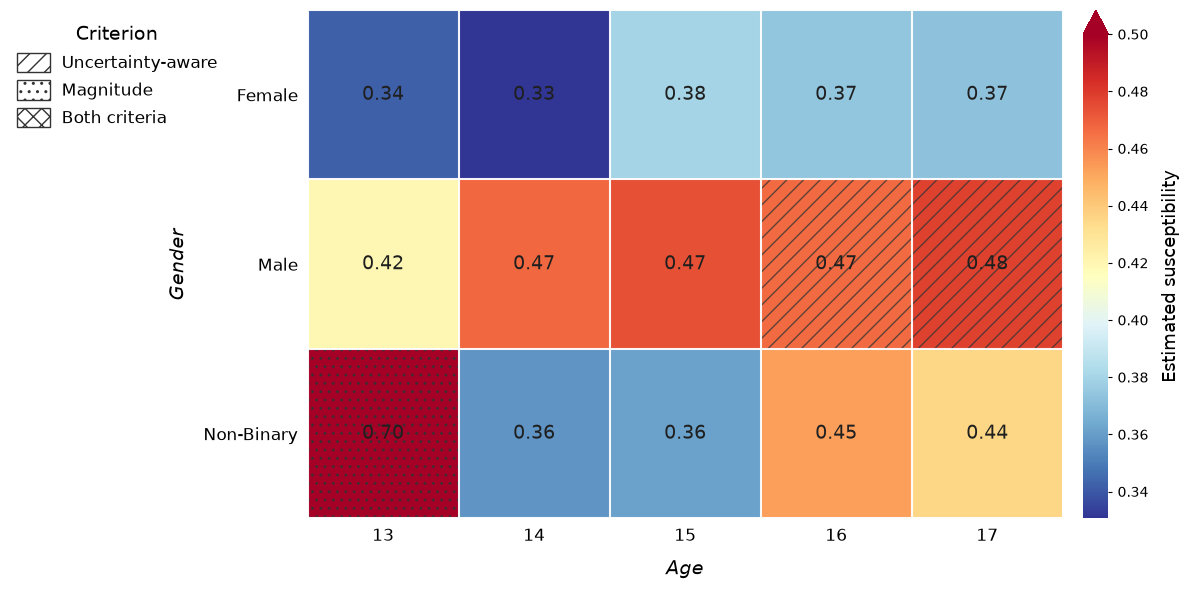

In [8]:

characteristic_cols=[
        "age",
        "gender",
    ]

characteristic_types=[
    "categorical",
    "categorical",
]

output_col="perc_R_Rplus_Rx_rec"

predictions, baseline, fig = assess_intersectional_susceptibility(
    df=df,
    characteristic_cols=characteristic_cols,
    characteristic_types=characteristic_types,
    output_col=output_col,
    continuous_model="spline",
    vmax=0.5
)


if fig is not None:

    fig.savefig(f'../results/{output_col}_by_{characteristic_cols[0]}_x_{characteristic_cols[1]}.pdf', bbox_inches='tight', pad_inches = 0)
    fig.savefig(f'../results/{output_col}_by_{characteristic_cols[0]}_x_{characteristic_cols[1]}.svg', bbox_inches='tight', pad_inches = 0)